In [56]:
import requests
import json

weather_url = "https://api.open-meteo.com/v1/forecast"
weather_params = {
    "latitude": 31.5497,
    "longitude": 74.3436,
    "hourly": "temperature_2m,relative_humidity_2m",
    "timezone": "Asia/Karachi",
}

r = requests.get(weather_url, params=weather_params)
print("Status:", r.status_code)

data = r.json()
print(data.keys())
print(json.dumps(data, indent=2)[:1500])


Status: 200
dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])
{
  "latitude": 31.528997,
  "longitude": 74.38995,
  "generationtime_ms": 0.0820159912109375,
  "utc_offset_seconds": 18000,
  "timezone": "Asia/Karachi",
  "timezone_abbreviation": "GMT+5",
  "elevation": 222.0,
  "hourly_units": {
    "time": "iso8601",
    "temperature_2m": "\u00b0C",
    "relative_humidity_2m": "%"
  },
  "hourly": {
    "time": [
      "2026-11-05T00:00",
      "2026-11-05T01:00",
      "2026-11-05T02:00",
      "2026-11-05T03:00",
      "2026-11-05T04:00",
      "2026-11-05T05:00",
      "2026-11-05T06:00",
      "2026-11-05T07:00",
      "2026-11-05T08:00",
      "2026-11-05T09:00",
      "2026-11-05T10:00",
      "2026-11-05T11:00",
      "2026-11-05T12:00",
      "2026-11-05T13:00",
      "2026-11-05T14:00",
      "2026-11-05T15:00",
      "2026-11-05T16:00",
      "2026-11-05T17:00",
      "20

In [57]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

df24 = hist.copy().dropna()

df24["hour"] = df24["time"].dt.hour
df24["aqi_lag1"] = df24["us_aqi"].shift(1)
df24["aqi_lag24"] = df24["us_aqi"].shift(24)   # kal isi waqt ka AQI
df24["target24"] = df24["us_aqi"].shift(-24)   # 24 ghante baad ka AQI

df24 = df24.dropna()

feats = ["hour", "pm2_5", "pm10", "aqi_lag1", "aqi_lag24"]
X = df24[feats]
y = df24["target24"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# baseline: "kal isi waqt jaisa AQI" ya "abhi jaisa"
print("Baseline (abhi jaisa) MAE:", mean_absolute_error(y_test, X_test["us_aqi"] if "us_aqi" in X_test else X_test["aqi_lag1"]))

lr = LinearRegression().fit(X_train, y_train)
print("Linear Regression MAE:", mean_absolute_error(y_test, lr.predict(X_test)))

Baseline (abhi jaisa) MAE: 22.858064516129033
Linear Regression MAE: 15.924552303864308


In [58]:
df = hist.copy()

# missing values hatao
df = df.dropna()

# naye columns (features)
df["hour"] = df["time"].dt.hour
df["aqi_lag1"] = df["us_aqi"].shift(1)      # pichle ghante ka AQI
df["pm25_lag1"] = df["pm2_5"].shift(1)      # pichle ghante ka PM2.5
df["target"] = df["us_aqi"].shift(-1)       # agle ghante ka AQI (jo predict karna hai)

df = df.dropna()
print(df.shape)
print(df.head())

(820, 8)
                 time  pm10  pm2_5  us_aqi  hour  aqi_lag1  pm25_lag1  target
1 2026-10-06 01:00:00  72.6   63.3   155.0     1     155.0       65.0   155.0
2 2026-10-06 02:00:00  71.7   62.4   155.0     2     155.0       63.3   154.0
3 2026-10-06 03:00:00  71.5   62.2   154.0     3     155.0       62.4   154.0
4 2026-10-06 04:00:00  71.0   61.7   154.0     4     154.0       62.2   154.0
5 2026-10-06 05:00:00  68.5   59.1   154.0     5     154.0       61.7   154.0


In [59]:
import joblib
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

rf_mae = mean_absolute_error(y_test, rf.predict(X_test))
lr_mae = mean_absolute_error(y_test, lr.predict(X_test))
print("Linear Regression MAE:", lr_mae)
print("Random Forest MAE:", rf_mae)

best = rf if rf_mae < lr_mae else lr
joblib.dump(best, "aqi_model_24h.pkl")
joblib.dump(feats, "features.pkl")
print("Saved model:", type(best).__name__)

Linear Regression MAE: 15.924552303864308
Random Forest MAE: 20.199612903225805
Saved model: LinearRegression


In [60]:
print("Baseline (abhi jaisa) MAE:", mean_absolute_error(y_test, X_test["aqi_lag1"]))
print("Baseline (kal isi waqt jaisa) MAE:", mean_absolute_error(y_test, X_test["aqi_lag24"]))

Baseline (abhi jaisa) MAE: 22.858064516129033
Baseline (kal isi waqt jaisa) MAE: 27.451612903225808


In [61]:
import requests
import pandas as pd

url = "https://air-quality-api.open-meteo.com/v1/air-quality"
params = {
    "latitude": 31.5497,
    "longitude": 74.3436,
    "hourly": "pm10,pm2_5,us_aqi",
    "past_days": 30,
    "timezone": "Asia/Karachi",
}

r = requests.get(url, params=params)
print("Status:", r.status_code)

hist = pd.DataFrame(r.json()["hourly"])
hist["time"] = pd.to_datetime(hist["time"])
print(hist.shape)
print(hist.describe())


Status: 200
(840, 4)
                                time        pm10       pm2_5      us_aqi
count                            840  822.000000  822.000000  823.000000
mean   2026-10-23 11:30:00.000000256   89.828954   73.168127  157.815310
min              2026-10-06 00:00:00   10.500000    9.300000   80.000000
25%              2026-10-14 17:45:00   56.500000   44.425000  144.000000
50%              2026-10-23 11:30:00   81.250000   64.500000  158.000000
75%              2026-11-01 05:15:00  117.800000   95.200000  172.000000
max              2026-11-09 23:00:00  292.400000  197.000000  215.000000
std                              NaN   45.215376   38.048672   25.637182


In [62]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

features = ["hour", "pm2_5", "pm10", "aqi_lag1", "pm25_lag1"]
X = df[features]
y = df["target"]

# time order mein baanto (shuffle nahi)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

model = LinearRegression()
model.fit(X_train, y_train)

pred = model.predict(X_test)
print("MAE:", mean_absolute_error(y_test, pred))

MAE: 2.357275936649129


In [63]:
baseline_pred = X_test["aqi_lag1"]
print("Baseline MAE:", mean_absolute_error(y_test, baseline_pred))

Baseline MAE: 2.231707317073171


In [64]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
print("Random Forest MAE:", mean_absolute_error(y_test, rf_pred))

Random Forest MAE: 5.883658536585366


In [65]:
import pandas as pd

aq_url = "https://air-quality-api.open-meteo.com/v1/air-quality"
aq_params = {
    "latitude": 31.5497,
    "longitude": 74.3436,
    "hourly": "pm10,pm2_5,us_aqi",
    "timezone": "Asia/Karachi",
}

r = requests.get(aq_url, params=aq_params)
print("Status:", r.status_code)

aq = r.json()
aq_df = pd.DataFrame(aq["hourly"])
aq_df["time"] = pd.to_datetime(aq_df["time"])
print(aq_df.head())
print(aq_df.shape)

Status: 200
                 time   pm10  pm2_5  us_aqi
0 2026-11-05 00:00:00  123.9  119.7   193.0
1 2026-11-05 01:00:00  123.4  119.2   193.0
2 2026-11-05 02:00:00  121.5  117.6   192.0
3 2026-11-05 03:00:00  119.7  115.5   191.0
4 2026-11-05 04:00:00  118.5  114.3   190.0
(120, 4)


In [66]:
y_train_d = y_train - X_train["aqi_lag1"]

rf2 = RandomForestRegressor(n_estimators=100, random_state=42)
rf2.fit(X_train, y_train_d)

rf2_pred = rf2.predict(X_test) + X_test["aqi_lag1"]
print("RF (change) MAE:", mean_absolute_error(y_test, rf2_pred))

RF (change) MAE: 3.4226829268292684


In [67]:
print(data["hourly"].keys())
print(data["hourly"]["time"][0])
print(data["hourly"]["temperature_2m"][0])


dict_keys(['time', 'temperature_2m', 'relative_humidity_2m'])
2026-11-05T00:00
20.7


In [68]:

print(data["hourly"]["time"][1])
print(data["hourly"]["temperature_2m"][1])
print(len(data["hourly"]["time"]))


2026-11-05T01:00
20.0
168


In [69]:
import pandas as pd

df = pd.DataFrame(data["hourly"])
print(df.head())
print(df.shape)


               time  temperature_2m  relative_humidity_2m
0  2026-11-05T00:00            20.7                    77
1  2026-11-05T01:00            20.0                    80
2  2026-11-05T02:00            19.6                    82
3  2026-11-05T03:00            19.5                    79
4  2026-11-05T04:00            19.3                    78
(168, 3)


In [70]:
df["time"] = pd.to_datetime(df["time"])
print(df.dtypes)
print(df["temperature_2m"].max(), df["temperature_2m"].min())

time                    datetime64[ns]
temperature_2m                 float64
relative_humidity_2m             int64
dtype: object
28.9 15.9


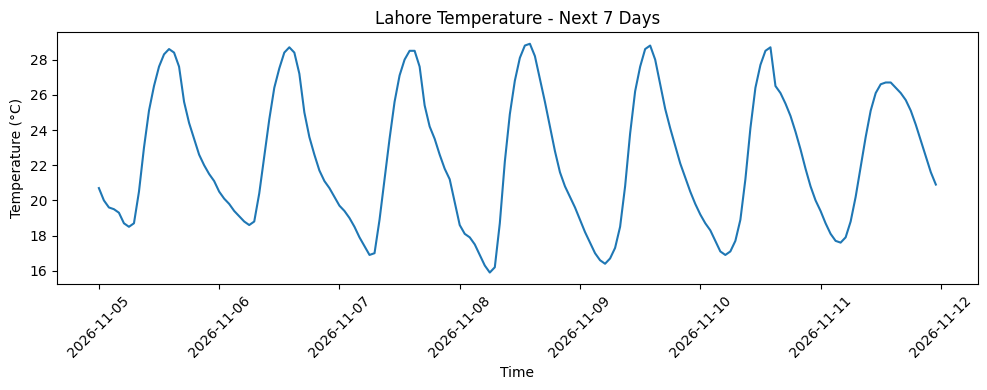

In [71]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(df["time"], df["temperature_2m"])
plt.title("Lahore Temperature - Next 7 Days")
plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

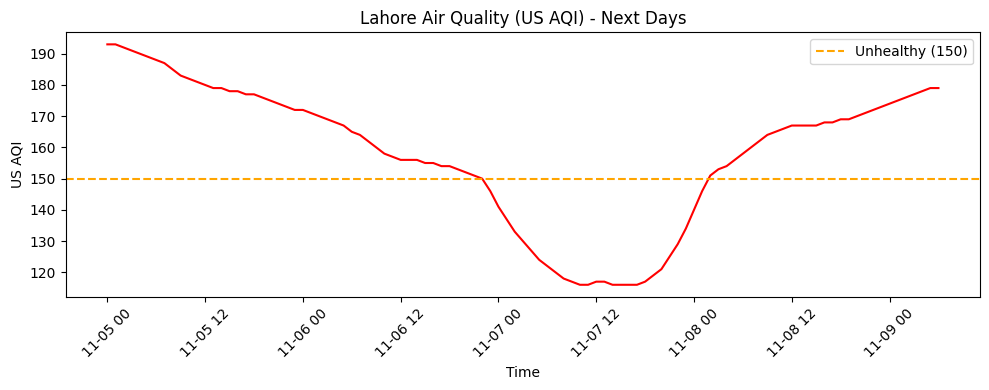

Max AQI: 193.0
Average AQI: 158.03883495145632


In [72]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(aq_df["time"], aq_df["us_aqi"], color="red")
plt.axhline(150, color="orange", linestyle="--", label="Unhealthy (150)")
plt.title("Lahore Air Quality (US AQI) - Next Days")
plt.xlabel("Time")
plt.ylabel("US AQI")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

print("Max AQI:", aq_df["us_aqi"].max())
print("Average AQI:", aq_df["us_aqi"].mean())